In [1]:
# 第一部分：导入必要的库（电脑B）
# ============================================

import mindspore as ms
from mindspore import nn
import mindspore.dataset as ds
import mindspore.ops as P
from mindspore.nn import SoftmaxCrossEntropyWithLogits
from mindspore.common.initializer import Normal

import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split

from mindquantum.core.circuit import Circuit, UN
from mindquantum.core.gates import H, RY, RZ, CNOT, Rxx, Ryy, Rzz
from mindquantum.core.parameterresolver import PRGenerator
from mindquantum.core.operators import QubitOperator, Hamiltonian
from mindquantum.simulator import Simulator
from mindquantum.framework import MQLayer
from mindspore import Tensor
import warnings
warnings.filterwarnings('ignore')

# 设置中文字体支持
plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

[WARNING] ME(26860:19084,MainProcess):2026-03-19-23:18:54.860.000 [mindspore\run_check\_check_version.py:543] The directory C:\Program Files\NVIDIA GPU Computing Toolkit\CUDA\v12.4 does not contain the typical file structure of CUDA
[ERROR] ME(26860:19084,MainProcess):2026-03-19-23:18:54.860.000 [mindspore\run_check\_check_version.py:582] CUDA_PATH C:\Program Files\NVIDIA GPU Computing Toolkit\CUDA\v12.4 is not safe, skip add cuda path.


In [2]:
# 第二部分：可调参数配置区（电脑B - PCA + 缩放实验）
# ============================================

# 数据相关参数
SAMPLE_RATIO = 1            # 数据采样比例
TEST_SIZE = 0.2                # 测试集比例
PCA_COMPONENTS = 8             # PCA降维维度（与量子比特数一致）
BATCH_SIZE = 32                 # 批处理大小

# 降维方法固定为PCA
DIM_REDUCTION_METHOD = 'pca'    # 固定降维方法

# 缩放层参数
ENABLE_LEARNABLE_SCALE = True   # 启用可学习缩放
SCALE_TYPES = ['scalar', 'diagonal', 'full']  # 三种缩放类型

# 量子电路参数
NUM_QUBITS = 8                  # 量子比特数
FIXED_ANSAYZ_TYPE = 'sequential_su4'  # 固定Ansatz类型
FIXED_LAYERS = 2                 # 固定层数

# 训练参数
NUM_EPOCHS = 150                 # 训练轮数
LEARNING_RATE = 0.01             # 学习率
PARALLEL_WORKER = 2              # 并行工作器数量

# MindSpore配置
MS_MODE = ms.PYNATIVE_MODE        # 运行模式
MS_DEVICE = "CPU"                 # 设备目标
SEED = 42                         # 随机种子

# 初始化设置
# ============================================
ms.set_context(mode=MS_MODE, device_target=MS_DEVICE)
ms.set_seed(SEED)
np.random.seed(SEED)

[WARNING] ME(26860:19084,MainProcess):2026-03-19-23:19:15.254.000 [mindspore\context.py:1334] For 'context.set_context', the parameter 'device_target' will be deprecated and removed in a future version. Please use the api mindspore.set_device() instead.


In [3]:
# 第三部分：数据加载和处理函数（电脑B - PCA降维）
# ============================================

from sklearn.preprocessing import MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
import mindspore.dataset as ds

def load_mnist_data():
    """加载MNIST数据集（与之前相同）"""
    import os
    from torchvision.datasets import MNIST
    
    print("正在下载/加载MNIST数据集...")
    data_dir = "./MNIST"
    os.makedirs(data_dir, exist_ok=True)
    
    try:
        train_set = MNIST(data_dir, train=True, download=True)
        test_set = MNIST(data_dir, train=False, download=True)
    except:
        import tempfile
        temp_dir = tempfile.gettempdir()
        data_dir = os.path.join(temp_dir, "MNIST")
        print(f"使用临时目录: {data_dir}")
        train_set = MNIST(data_dir, train=True, download=True)
        test_set = MNIST(data_dir, train=False, download=True)
    
    def extract_data(dataset):
        images = dataset.data.numpy().astype(np.float32) / 255.0
        labels = dataset.targets.numpy()
        images_flatten = images.reshape(len(images), -1)
        return images_flatten, labels
    
    train_images, train_labels = extract_data(train_set)
    test_images, test_labels = extract_data(test_set)
    
    # 合并数据并采样
    all_images = np.concatenate([train_images, test_images])
    all_labels = np.concatenate([train_labels, test_labels])
    sampled_indices = np.random.choice(
        len(all_images), 
        int(len(all_images) * SAMPLE_RATIO), 
        replace=False
    )
    sampled_images = all_images[sampled_indices]
    sampled_labels = all_labels[sampled_indices]
    
    print(f"总样本数: {len(all_images)}, 采样后: {len(sampled_images)}")
    print(f"类别分布: {np.unique(sampled_labels, return_counts=True)}")
    
    return sampled_images, sampled_labels

def preprocess_data_pca(images, labels, scaler=None, pca=None, is_train=True):
    """
    PCA降维 + 归一化到[-1,1]预处理函数
    返回: (dataset, scaler, pca)
    """
    if is_train:
        # 训练集：训练PCA和Scaler
        pca = PCA(n_components=PCA_COMPONENTS)
        pca_data = pca.fit_transform(images)
        print(f"PCA解释方差比: {np.sum(pca.explained_variance_ratio_):.4f}")
        
        # 归一化到[-1, 1]
        scaler = MinMaxScaler(feature_range=(-1, 1))
        normalized_data = scaler.fit_transform(pca_data)
    else:
        # 测试集：使用训练好的模型
        pca_data = pca.transform(images)
        normalized_data = scaler.transform(pca_data)
    
    # 创建MindSpore数据集
    dataset = ds.NumpySlicesDataset(
        data=(normalized_data.astype(np.float32), labels.astype(np.int32)),
        column_names=["features", "labels"],
        shuffle=is_train
    ).batch(BATCH_SIZE)
    
    return dataset, scaler, pca

In [4]:
# 第四部分：量子电路构建函数（通用）
# ============================================

def build_encoder():
    """构建编码器电路（固定）"""
    prg = PRGenerator('alpha')
    encoder = Circuit()
    encoder += UN(H, NUM_QUBITS)
    
    for i in range(NUM_QUBITS):
        encoder += RY(prg.new()).on(i)
    
    # 局部 Brickwall 纠缠（一层即可）
    for i in range(0, NUM_QUBITS - 1, 2):
        encoder += CNOT.on(i + 1, i)
    for i in range(1, NUM_QUBITS - 1, 2):
        encoder += CNOT.on(i + 1, i)
    
    encoder = encoder.no_grad()
    encoder.as_encoder()
    return encoder

def build_sequential_su4_ansatz(num_layers):
    """构建顺序SU4 Ansatz（固定使用此结构）"""
    theta_prg = PRGenerator('theta')
    ansatz = Circuit()
    
    for layer in range(num_layers):
        # 单比特旋转层
        for qubit in range(NUM_QUBITS):
            ansatz += RY(theta_prg.new()).on(qubit)
            ansatz += RZ(theta_prg.new()).on(qubit)
        
        # 顺序两比特门层
        for i in range(NUM_QUBITS - 1):
            ansatz += Rxx(theta_prg.new()).on([i, i + 1])
            ansatz += Ryy(theta_prg.new()).on([i, i + 1])
            ansatz += Rzz(theta_prg.new()).on([i, i + 1])
            
            ansatz += RY(theta_prg.new()).on(i)
            ansatz += RZ(theta_prg.new()).on(i)
            ansatz += RY(theta_prg.new()).on(i + 1)
            ansatz += RZ(theta_prg.new()).on(i + 1)
    
    # 最终单比特层
    for qubit in range(NUM_QUBITS):
        ansatz += RZ(theta_prg.new()).on(qubit)
        ansatz += RY(theta_prg.new()).on(qubit)
    
    ansatz.as_ansatz()
    return ansatz

def build_ansatz():
    """根据固定参数构建Ansatz"""
    return build_sequential_su4_ansatz(FIXED_LAYERS)

def create_hamiltonians():
    """创建测量哈密顿量 - 仅测量单比特Z"""
    hams = []
    for i in range(NUM_QUBITS):
        hams.append(Hamiltonian(QubitOperator(f'Z{i}', 1.0)))
    return hams

In [5]:
# 第五部分：神经网络定义与训练（通用）
# ============================================

class LearnableScaler(nn.Cell):
    """可学习的缩放层（输入特征降维后使用）"""
    def __init__(self, input_dim=PCA_COMPONENTS, scale_type="diagonal"):
        super(LearnableScaler, self).__init__()
        self.scale_type = scale_type
        self.input_dim = input_dim
        
        if scale_type == "scalar":
            # 标量缩放：所有维度使用同一个缩放因子
            self.scale = ms.Parameter(Tensor(np.ones(1) * 1.0, dtype=ms.float32))
            self.bias = ms.Parameter(Tensor(np.zeros(1), dtype=ms.float32))
            print(f"  缩放类型: 标量缩放 (1个缩放参数)")
            
        elif scale_type == "diagonal":
            # 对角缩放：每个维度有自己的缩放因子
            self.scale = ms.Parameter(Tensor(np.ones(input_dim) * 1.0, dtype=ms.float32))
            self.bias = ms.Parameter(Tensor(np.zeros(input_dim), dtype=ms.float32))
            print(f"  缩放类型: 对角缩放 ({input_dim}个缩放参数)")
            
        elif scale_type == "full":
            # 全连接缩放：使用线性变换
            self.linear = nn.Dense(input_dim, input_dim, has_bias=True)
            print(f"  缩放类型: 全连接缩放 ({input_dim * input_dim + input_dim}个参数)")
        else:
            raise ValueError(f"未知的缩放类型: {scale_type}")
    
    def construct(self, x):
        if self.scale_type == "scalar":
            return x * self.scale + self.bias
        elif self.scale_type == "diagonal":
            return x * self.scale + self.bias
        elif self.scale_type == "full":
            return self.linear(x)
        return x


class HybridQuantumNet(nn.Cell):
    """混合量子-经典神经网络（含可学习缩放层）"""
    def __init__(self, quantum_net, scale_type, num_classes=10):
        super(HybridQuantumNet, self).__init__()
        self.quantum_net = quantum_net
        
        # 可学习缩放层（如果启用）
        if ENABLE_LEARNABLE_SCALE:
            self.scaler = LearnableScaler(PCA_COMPONENTS, scale_type)
        else:
            self.scaler = None
        
        # 测量维度 = 量子比特数
        self.fc = nn.Dense(NUM_QUBITS, num_classes, weight_init=Normal(0.02))
        
    def construct(self, x):
        # 确保输入为二维 [batch_size, features]
        if len(x.shape) == 1:
            x = x.reshape(1, -1)
        elif len(x.shape) > 2:
            x = x.reshape(x.shape[0], -1)
        
        # 应用可学习缩放
        if self.scaler is not None:
            x = self.scaler(x)
        
        # 量子层输出Z测量值，形状 [batch_size, NUM_QUBITS]
        quantum_out = self.quantum_net(x)
        # 分类
        logits = self.fc(quantum_out)
        return logits


def train_model(train_dataset, val_dataset, scale_type,
                num_epochs=NUM_EPOCHS, learning_rate=LEARNING_RATE):
    """
    训练模型（固定使用 sequential_su4, 2层，但缩放类型可变）
    参数：
        train_dataset: 训练数据集
        val_dataset: 验证数据集
        scale_type: 缩放类型，如 'scalar', 'diagonal', 'full'
    """
    print(f"\n开始训练: Ansatz类型={FIXED_ANSAYZ_TYPE}, 层数={FIXED_LAYERS}, 缩放类型={scale_type}")
    
    # 构建量子电路
    print("构建量子电路...")
    encoder = build_encoder()
    ansatz = build_ansatz()  # 使用固定层数
    full_circuit = encoder + ansatz
    
    print("量子电路构建完成:")
    print(f"  编码器: {encoder.n_qubits}量子比特")
    print(f"  Ansatz: {ansatz.n_qubits}量子比特，{FIXED_LAYERS}层")
    
    # 创建哈密顿量和梯度算子（仅Z测量）
    print("创建哈密顿量和梯度算子...")
    hams = create_hamiltonians()
    print(f"  哈密顿量数量: {len(hams)} (单比特Z)")
    
    sim = Simulator('mqvector', NUM_QUBITS)
    grad_ops = sim.get_expectation_with_grad(
        hams, full_circuit, parallel_worker=PARALLEL_WORKER
    )
    
    # 创建量子层和混合网络
    print("创建神经网络...")
    quantum_net = MQLayer(grad_ops)
    net = HybridQuantumNet(quantum_net, scale_type=scale_type, num_classes=10)
    
    # 损失函数和优化器
    loss_fn = SoftmaxCrossEntropyWithLogits(sparse=True, reduction='mean')
    optimizer = nn.Adam(net.trainable_params(), learning_rate=learning_rate)
    
    # 定义前向传播和梯度函数
    def forward_fn(data, label):
        if len(data.shape) == 1:
            data = data.reshape(1, -1)
        logits = net(data)
        loss = loss_fn(logits, label)
        return loss, logits
    
    grad_fn = ms.value_and_grad(forward_fn, None, optimizer.parameters, has_aux=True)
    
    # 训练循环
    train_losses = []
    val_accuracies = []
    best_val_acc = 0.0
    
    print(f"\n开始训练循环 ({num_epochs} epochs)...")
    
    for epoch in range(num_epochs):
        # 训练
        net.set_train()
        epoch_loss = 0
        step = 0
        
        for data, label in train_dataset.create_tuple_iterator():
            (loss, _), grads = grad_fn(data, label)
            optimizer(grads)
            epoch_loss += loss.asnumpy()
            step += 1
        
        avg_loss = epoch_loss / step if step > 0 else 0
        train_losses.append(avg_loss)
        
        # 验证
        net.set_train(False)
        correct = 0
        total = 0
        
        for data, label in val_dataset.create_tuple_iterator():
            if len(data.shape) == 1:
                data = data.reshape(1, -1)
            logits = net(data)
            predict = ms.ops.Argmax(output_type=ms.int32)(logits)
            correct += (predict == label).asnumpy().sum()
            total += len(label)
        
        val_acc = correct / total if total > 0 else 0
        val_accuracies.append(val_acc)
        
        if val_acc > best_val_acc:
            best_val_acc = val_acc
        
        # 打印进度
        if (epoch + 1) % 10 == 0 or epoch == 0 or epoch == num_epochs - 1:
            print(f"Epoch {epoch+1:3d}/{num_epochs}: "
                  f"训练损失={avg_loss:.4f}, 验证准确率={val_acc:.4f}")
    
    print(f"\n训练完成! 最佳验证准确率: {best_val_acc:.4f}")
    
    return train_losses, val_accuracies, best_val_acc

PCA降维 + 可学习缩放实验 - 固定Ansatz: sequential_su4, 层数=2

步骤1：加载MNIST数据
正在下载/加载MNIST数据集...
总样本数: 70000, 采样后: 70000
类别分布: (array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9], dtype=int64), array([6903, 7877, 6990, 7141, 6824, 6313, 6876, 7293, 6825, 6958],
      dtype=int64))
数据大小: 70000

步骤2：划分训练集和测试集
训练集: 56000 样本, 测试集: 14000 样本

步骤3：PCA降维预处理
PCA解释方差比: 0.4384
PCA降维和归一化完成，数据集已准备好。

实验: 缩放类型 = scalar

开始训练: Ansatz类型=sequential_su4, 层数=2, 缩放类型=scalar
构建量子电路...
量子电路构建完成:
  编码器: 8量子比特
  Ansatz: 8量子比特，2层
创建哈密顿量和梯度算子...
  哈密顿量数量: 8 (单比特Z)
创建神经网络...
  缩放类型: 标量缩放 (1个缩放参数)

开始训练循环 (150 epochs)...
Epoch   1/150: 训练损失=1.0292, 验证准确率=0.7722
Epoch  10/150: 训练损失=0.5875, 验证准确率=0.8158
Epoch  20/150: 训练损失=0.5643, 验证准确率=0.8210
Epoch  30/150: 训练损失=0.5528, 验证准确率=0.8257
Epoch  40/150: 训练损失=0.5424, 验证准确率=0.8319
Epoch  50/150: 训练损失=0.5322, 验证准确率=0.8358
Epoch  60/150: 训练损失=0.5248, 验证准确率=0.8351
Epoch  70/150: 训练损失=0.5202, 验证准确率=0.8363
Epoch  80/150: 训练损失=0.5170, 验证准确率=0.8375
Epoch  90/150: 训练损失=0.5153, 验证准确率=0.8380
Epoch 100/150: 训练

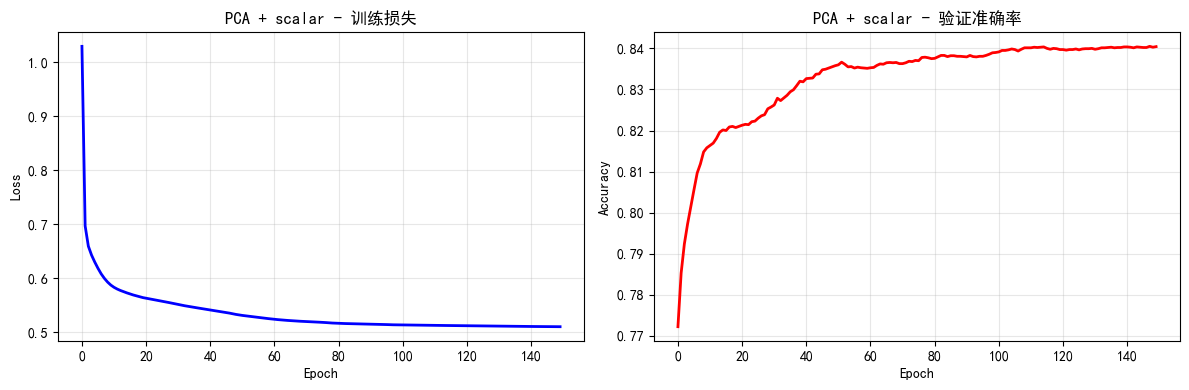


实验: 缩放类型 = diagonal

开始训练: Ansatz类型=sequential_su4, 层数=2, 缩放类型=diagonal
构建量子电路...
量子电路构建完成:
  编码器: 8量子比特
  Ansatz: 8量子比特，2层
创建哈密顿量和梯度算子...
  哈密顿量数量: 8 (单比特Z)
创建神经网络...
  缩放类型: 对角缩放 (8个缩放参数)

开始训练循环 (150 epochs)...
Epoch   1/150: 训练损失=1.0558, 验证准确率=0.7723
Epoch  10/150: 训练损失=0.5909, 验证准确率=0.8129
Epoch  20/150: 训练损失=0.5540, 验证准确率=0.8183
Epoch  30/150: 训练损失=0.5390, 验证准确率=0.8256
Epoch  40/150: 训练损失=0.5295, 验证准确率=0.8288
Epoch  50/150: 训练损失=0.5230, 验证准确率=0.8346
Epoch  60/150: 训练损失=0.5169, 验证准确率=0.8376
Epoch  70/150: 训练损失=0.5116, 验证准确率=0.8416
Epoch  80/150: 训练损失=0.5083, 验证准确率=0.8439
Epoch  90/150: 训练损失=0.5059, 验证准确率=0.8447
Epoch 100/150: 训练损失=0.5041, 验证准确率=0.8450
Epoch 110/150: 训练损失=0.5028, 验证准确率=0.8443
Epoch 120/150: 训练损失=0.5018, 验证准确率=0.8440
Epoch 130/150: 训练损失=0.5011, 验证准确率=0.8436
Epoch 140/150: 训练损失=0.5005, 验证准确率=0.8435
Epoch 150/150: 训练损失=0.5001, 验证准确率=0.8441

训练完成! 最佳验证准确率: 0.8452


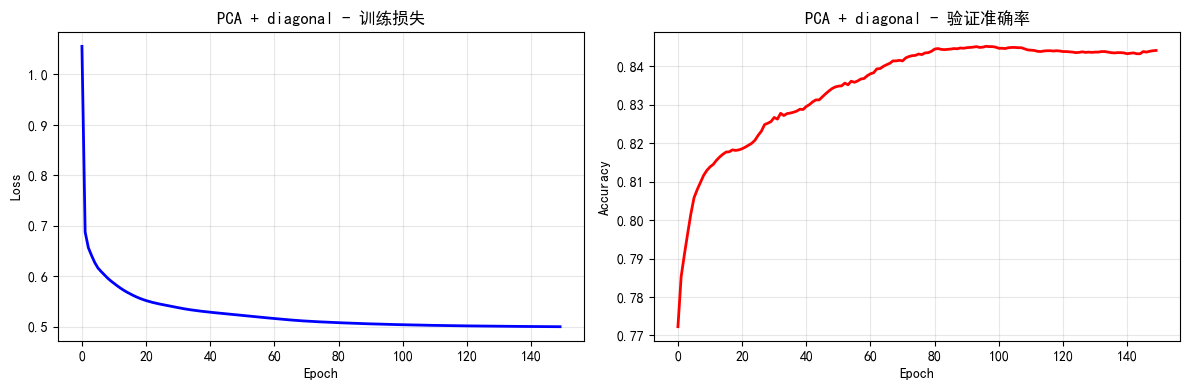


实验: 缩放类型 = full

开始训练: Ansatz类型=sequential_su4, 层数=2, 缩放类型=full
构建量子电路...
量子电路构建完成:
  编码器: 8量子比特
  Ansatz: 8量子比特，2层
创建哈密顿量和梯度算子...
  哈密顿量数量: 8 (单比特Z)
创建神经网络...
  缩放类型: 全连接缩放 (72个参数)

开始训练循环 (150 epochs)...
Epoch   1/150: 训练损失=1.5192, 验证准确率=0.6316
Epoch  10/150: 训练损失=0.8932, 验证准确率=0.6988
Epoch  20/150: 训练损失=0.8229, 验证准确率=0.7271
Epoch  30/150: 训练损失=0.7922, 验证准确率=0.7387
Epoch  40/150: 训练损失=0.7719, 验证准确率=0.7439
Epoch  50/150: 训练损失=0.7603, 验证准确率=0.7513
Epoch  60/150: 训练损失=0.7495, 验证准确率=0.7529
Epoch  70/150: 训练损失=0.7414, 验证准确率=0.7544
Epoch  80/150: 训练损失=0.7357, 验证准确率=0.7566
Epoch  90/150: 训练损失=0.7306, 验证准确率=0.7592
Epoch 100/150: 训练损失=0.7277, 验证准确率=0.7595
Epoch 110/150: 训练损失=0.7246, 验证准确率=0.7599
Epoch 120/150: 训练损失=0.7235, 验证准确率=0.7591
Epoch 130/150: 训练损失=0.7219, 验证准确率=0.7599
Epoch 140/150: 训练损失=0.7206, 验证准确率=0.7591
Epoch 150/150: 训练损失=0.7192, 验证准确率=0.7594

训练完成! 最佳验证准确率: 0.7636


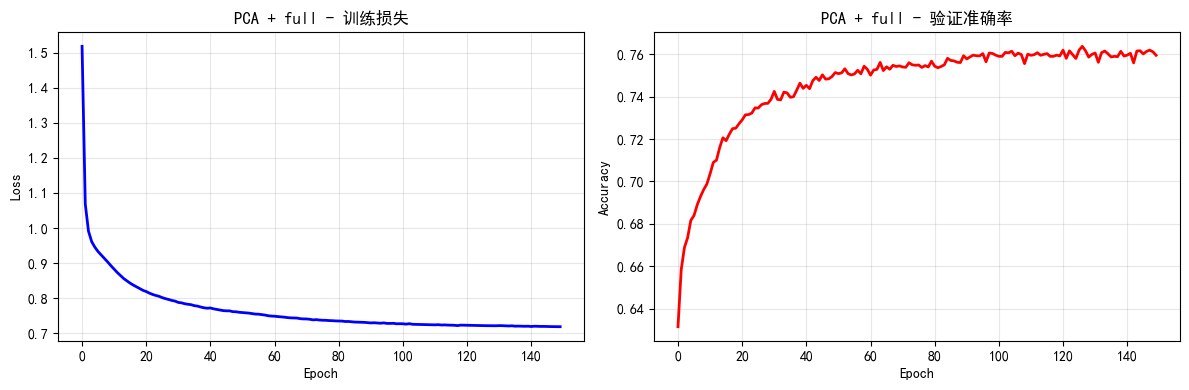


实验结果汇总 (PCA + 缩放)
scalar: 最佳验证准确率 = 0.8405
diagonal: 最佳验证准确率 = 0.8452
full: 最佳验证准确率 = 0.7636

所有结果已保存到 pca_scaling_results.npz


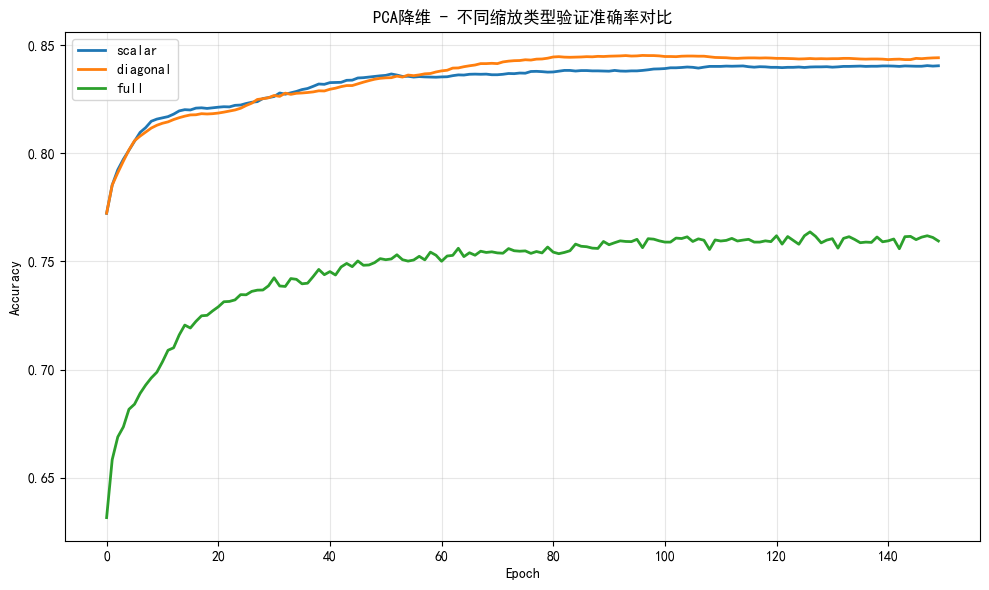

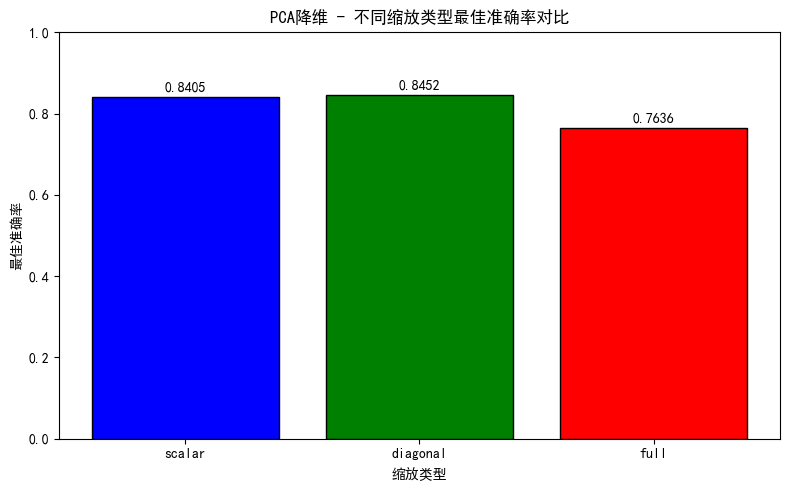

In [6]:
# 第六部分：主程序 - PCA降维 + 三种缩放方式实验
# ============================================

if __name__ == "__main__":
    print("=" * 60)
    print("PCA降维 + 可学习缩放实验 - 固定Ansatz: sequential_su4, 层数=2")
    print("=" * 60)

    # 1. 加载数据
    print("\n步骤1：加载MNIST数据")
    all_images, all_labels = load_mnist_data()
    print(f"数据大小: {len(all_images)}")

    # 2. 划分数据集
    print("\n步骤2：划分训练集和测试集")
    train_images, test_images, train_labels, test_labels = train_test_split(
        all_images, all_labels, test_size=TEST_SIZE, random_state=SEED, stratify=all_labels
    )
    print(f"训练集: {len(train_images)} 样本, 测试集: {len(test_images)} 样本")

    # 3. 一次性完成PCA降维预处理，得到训练和测试数据集
    print("\n步骤3：PCA降维预处理")
    train_dataset, scaler, pca = preprocess_data_pca(
        train_images, train_labels, is_train=True
    )
    test_dataset, _, _ = preprocess_data_pca(
        test_images, test_labels, scaler=scaler, pca=pca, is_train=False
    )
    print("PCA降维和归一化完成，数据集已准备好。")

    # 4. 遍历三种缩放类型进行实验
    all_results = {}  # 键为 scale_type

    for scale_type in SCALE_TYPES:
        print(f"\n{'='*60}")
        print(f"实验: 缩放类型 = {scale_type}")
        print(f"{'='*60}")

        # 训练模型
        train_losses, val_accuracies, best_val_acc = train_model(
            train_dataset=train_dataset,
            val_dataset=test_dataset,
            scale_type=scale_type,
            num_epochs=NUM_EPOCHS,
            learning_rate=LEARNING_RATE
        )

        # 存储结果
        all_results[scale_type] = {
            'train_losses': train_losses,
            'val_accuracies': val_accuracies,
            'best_val_acc': best_val_acc
        }

        # 5. 绘制单个实验的曲线
        plt.figure(figsize=(12, 4))
        plt.subplot(1, 2, 1)
        plt.plot(train_losses, 'b-', linewidth=2)
        plt.title(f'PCA + {scale_type} - 训练损失')
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.grid(True, alpha=0.3)

        plt.subplot(1, 2, 2)
        plt.plot(val_accuracies, 'r-', linewidth=2)
        plt.title(f'PCA + {scale_type} - 验证准确率')
        plt.xlabel('Epoch')
        plt.ylabel('Accuracy')
        plt.grid(True, alpha=0.3)
        plt.tight_layout()
        plt.show()

    # 6. 汇总结果
    print("\n" + "=" * 60)
    print("实验结果汇总 (PCA + 缩放)")
    print("=" * 60)
    for scale_type, res in all_results.items():
        print(f"{scale_type}: 最佳验证准确率 = {res['best_val_acc']:.4f}")

    # 7. 保存所有结果
    np.savez('pca_scaling_results.npz',
             scale_types=SCALE_TYPES,
             train_losses={st: all_results[st]['train_losses'] for st in SCALE_TYPES},
             val_accuracies={st: all_results[st]['val_accuracies'] for st in SCALE_TYPES},
             best_val_accs={st: all_results[st]['best_val_acc'] for st in SCALE_TYPES})
    print("\n所有结果已保存到 pca_scaling_results.npz")

    # 8. 绘制所有缩放类型的对比曲线
    plt.figure(figsize=(10, 6))
    for scale_type in SCALE_TYPES:
        plt.plot(all_results[scale_type]['val_accuracies'], label=scale_type, linewidth=2)
    plt.title('PCA降维 - 不同缩放类型验证准确率对比')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(8, 5))
    best_accs = [all_results[st]['best_val_acc'] for st in SCALE_TYPES]
    plt.bar(SCALE_TYPES, best_accs, color=['blue', 'green', 'red'], edgecolor='black')
    plt.title('PCA降维 - 不同缩放类型最佳准确率对比')
    plt.xlabel('缩放类型')
    plt.ylabel('最佳准确率')
    plt.ylim(0, 1.0)
    for i, acc in enumerate(best_accs):
        plt.text(i, acc + 0.01, f'{acc:.4f}', ha='center', va='bottom')
    plt.tight_layout()
    plt.show()